<a href="https://colab.research.google.com/github/codus10/nova3-2/blob/main/20244334_%EB%AA%A8%EC%B1%84%EC%97%B0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 범주형 데이터 분석: 그룹별 패턴 찾기

```
학번: 20244334
이름: 모채연
```

# 🎯 PART 1. 핵심 개념 단답형 문제

1. 성별, 지역, 혈액형처럼 몇 개의 그룹(category)으로 구분되는 데이터를 **( 범주형 ) 데이터** 라고 합니다.

2. 평균, 합계, 최댓값처럼 데이터를 요약된 통계량으로 계산하는 과정을 **( 집계 )** 이라고 합니다.

3. `groupby`의 핵심 원리인 Split → Apply → Combine 중 데이터를 기준별로 나누는 단계를 **( Split )** 이라고 합니다.

4. `groupby`에서 각 그룹에 평균이나 합계를 계산하는 단계를 **( Apply )** 이라고 합니다.

5. `groupby` 계산 결과를 다시 하나의 표로 합치는 단계를 **( Combine )** 이라고 합니다.

6. `groupby()` 결과를 엑셀 형태의 가로·세로 표로 변환하는 기능을 **( 피벗 ) 테이블** 이라고 합니다.

7. 머신러닝 모델은 문자열(text)을 직접 이해하지 못하기 때문에 범주형 데이터를 **( 숫자 )** 로 변환해야 합니다.

8. 범주형 데이터를 숫자 0, 1, 2처럼 단순 정수로 변환하는 방법을 **( Label ) Encoding** 이라고 합니다.

9. 범주형 데이터를 여러 개의 0과 1 컬럼으로 나누어 표현하는 방법을 **( One-Hot ) Encoding** 이라고 합니다.

10. 머신러닝에서 One-Hot Encoding을 사용하는 가장 중요한 이유는 범주 간의 **( 순서 ) 관계** 를 제거하기 위해서입니다.

11. Seaborn에서 범주별 데이터 개수를 자동으로 세어 막대그래프로 그려주는 함수는 `( countplot )` 입니다.

12. Seaborn의 `barplot()`에서 색깔 기준으로 그룹을 나누는 옵션 이름은 **( hue )** 입니다.

13. `agg()` 함수는 여러 개의 **( 집계 ) 함수** 를 한 번에 적용할 때 사용합니다.

14. `tips` 데이터셋에서 `sex`, `smoker`, `day`, `time` 컬럼은 모두 **( 범주형 ) 데이터** 입니다.

15. 머신러닝에서 범주형 데이터는 고객 그룹, 지역별 패턴 등 중요한 **( 패턴 ) 정보** 를 담고 있습니다.

---


# 🎯 PART 2. 코드 결과 예측하기 — 눈으로 디버깅하기 (8문제)

---

## 문제 1. groupby 평균 계산

```python
df.groupby('sex')['tip'].mean()
```

* **예상 결과:** `sex` 그룹별 **( 팁 ) 평균** 이 계산된다.

---

## 문제 2. 여러 통계량 계산

```python
df.groupby('smoker')['tip'].agg(['mean', 'max', 'count'])
```

* **예상 결과:** 흡연 여부별 tip의 **( 평균 )**, **( 최댓값 )**, **( 개수 )** 가 동시에 계산된다.

---

## 문제 3. 다중 그룹 분석

```python
df.groupby(['sex', 'smoker'])['tip'].mean()
```

* **예상 결과:** 성별과 흡연 여부 기준으로 그룹을 나누어 **( 팁 ) 평균** 을 계산한다.

---

## 문제 4. pivot_table

```python id="rrq0xy"
pd.pivot_table(
    df,
    index='sex',
    columns='smoker',
    values='tip',
    aggfunc='mean'
)
```

* **예상 결과:** 행은 **( 성별 )**, 열은 **( 흡연여부 )**, 값은 tip 평균으로 구성된 표가 만들어진다.

---

## 문제 5. One-Hot Encoding

```python
pd.get_dummies(df['day'])
```

* **예상 결과:** `day` 컬럼이 여러 개의 **( 0과 1 ) 컬럼** 으로 변환된다.

---

## 문제 6. countplot

```python
sns.countplot(data=df, x='day')
```

* **예상 결과:** 요일(day)별 데이터 **( 개수 )** 가 막대그래프로 시각화된다.

---

## 문제 7. hue 옵션

```python
sns.barplot(
    data=df,
    x='day',
    y='tip',
    hue='sex'
)
```

* **예상 결과:** 요일별 평균 tip이 성별에 따라 다른 **( 색깔 막대 )** 으로 표시된다.

---

## 문제 8. Feature 설정

```python id="d1kxy9"
X = df[['total_bill', 'size']]
y = df['tip']
```

* **예상 결과:** `X`는 머신러닝 입력 데이터인 **( 특징 )** 이고, `y`는 예측 목표인 **( 타깃 )** 이다.
---

# 🎯 PART 3. 실습 과제

---

# 실습 과제 1. 쇼핑몰 고객 구매 패턴 분석

## 목표

고객 데이터를 그룹별로 분석하여:

* 어떤 지역 고객이 구매를 많이 하는지
* 어떤 연령대가 소비가 높은지

분석하기

## STEP 1. 데이터 생성

```text
고객 100명의 가상 쇼핑몰 데이터를 생성해줘.

컬럼:
- 연령대(20대, 30대, 40대)
- 지역(서울, 경기, 부산)
- 회원등급(VIP, GOLD, SILVER)
- 구매금액

으로 구성해줘.
```

## STEP 2. 데이터 분석

```text
생성한 데이터의
head(), info(), describe()를 출력하고,
각 컬럼이 범주형인지 숫자형인지 설명해줘.
```

## STEP 3. Groupby 분석

```text
지역별 평균 구매금액을 groupby로 계산해줘.
```

## STEP 4. 다중 그룹 분석

```text
['연령대', '회원등급'] 기준으로 groupby를 수행하고,
구매금액 평균을 계산해줘.
```

## STEP 5. Pivot Table

```text
행은 연령대,
열은 회원등급,
값은 구매금액 평균이 되도록
pivot_table을 만들어줘.
```

## STEP 6. 시각화

```text
지역별 평균 구매금액을
barplot으로 시각화해줘.
```

---

## STEP 7. 히트맵 시각화

```tex
pivot_table 결과를 heatmap으로 시각화해줘.
```

---

In [ ]:
#STEP 1. 데이터 생성

import pandas as pd
import numpy as np

np.random.seed(42)

data = {
    '연령대': np.random.choice(['20대', '30대', '40대'], 100),
    '지역': np.random.choice(['서울', '경기', '부산'], 100),
    '회원등급': np.random.choice(['VIP', 'GOLD', 'SILVER'], 100),
    '구매금액': np.random.randint(10000, 100000, 100)
}

df = pd.DataFrame(data)


In [ ]:
#STEP 2. 데이터 분석

print(df.info())
print(df.describe())
print(df.head())
print(df.info())
print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   연령대     100 non-null    object
 1   지역      100 non-null    object
 2   회원등급    100 non-null    object
 3   구매금액    100 non-null    int64 
dtypes: int64(1), object(3)
memory usage: 3.3+ KB
None
              구매금액
count    100.00000
mean   53947.06000
std    26132.96049
min    10301.00000
25%    29807.00000
50%    55380.50000
75%    76137.50000
max    99912.00000
   연령대  지역  회원등급   구매금액
0  40대  부산   VIP  71135
1  20대  부산  GOLD  60108
2  40대  부산   VIP  48467
3  40대  서울  GOLD  33328
4  20대  부산  GOLD  96831
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   연령대     100 non-null    object
 1   지역      100 non-null    object
 2   회원등급    100 non-null    object
 3   구매금액    100 non-null   

In [ ]:
#STEP 3. Groupby 분석

df.groupby('지역')['구매금액'].mean()

,구매금액
지역,
경기,52552.800000
부산,55079.833333
서울,53561.606061


In [ ]:
#STEP 4. 다중 그룹 분석

df.groupby(['연령대', '회원등급'])['구매금액'].mean()

연령대  회원등급  
20대  GOLD      47907.571429
     SILVER    58123.111111
     VIP       53137.300000
30대  GOLD      45155.384615
     SILVER    48397.466667
     VIP       54620.375000
40대  GOLD      63541.666667
     SILVER    54797.200000
     VIP       66023.466667
Name: 구매금액, dtype: float64

In [ ]:
#STEP 5. Pivot Table

pd.pivot_table(
    df,
    index='연령대',
    columns='회원등급',
    values='구매금액',
    aggfunc='mean'
)

회원등급,GOLD,SILVER,VIP
연령대,,,
20대,47907.571429,58123.111111,53137.300000
30대,45155.384615,48397.466667,54620.375000
40대,63541.666667,54797.200000,66023.466667


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 48512 (\N{HANGUL SYLLABLE BU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49328 (\N{HANGUL SYLLABLE SAN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49436 (\N{HANGUL SYLLABLE SEO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 50872 (\N{HANGUL SYLLABLE UL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44221 (\N{HANGUL SYLLABLE GYEONG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr

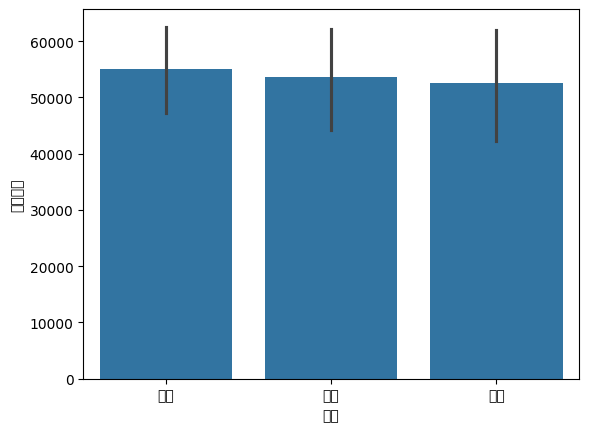

In [ ]:
#STEP 6. 시각화 (Barplot)
import seaborn as sns
import matplotlib.pyplot as plt

sns.barplot(data=df, x='지역', y='구매금액', estimator=np.mean)
plt.show()

/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 45824 (\N{HANGUL SYLLABLE DAE}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 54924 (\N{HANGUL SYLLABLE HOE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 50896 (\N{HANGUL SYLLABLE WEON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 46321 (\N{HANGUL SYLLABLE DEUNG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44553 (\N{HANGUL SYLLABLE GEUB}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-pac

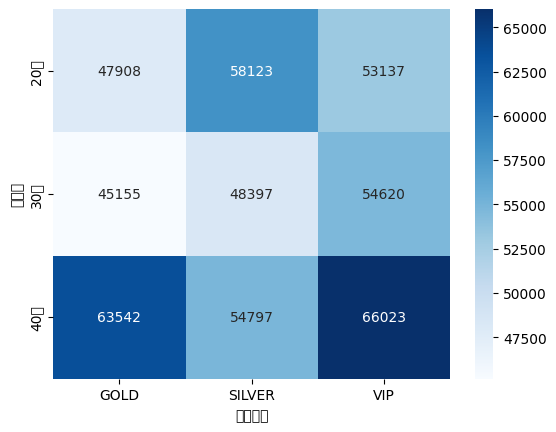

In [ ]:
#STEP 7. 히트맵 시각화

pivot = pd.pivot_table(
    df,
    index='연령대',
    columns='회원등급',
    values='구매금액',
    aggfunc='mean'
)

sns.heatmap(pivot, annot=True, fmt='.0f', cmap='Blues')
plt.show()

# 🎯 실습 과제 2. Diamonds 데이터셋 기반 머신러닝 회귀 분석

## 목표

범주형 데이터를 포함하여:

**다이아몬드 가격(price) 예측 모델**

만들기

---

## 사용할 데이터셋

Seaborn의 `diamonds` 데이터셋 사용.

---

## 주요 컬럼

| 컬럼      | 의미     | 데이터 타입      |
| ------- | ------ | ----------- |
| carat   | 다이아 크기 | 숫자형         |
| depth   | 깊이     | 숫자형         |
| table   | 테이블 비율 | 숫자형         |
| price   | 가격     | 숫자형(Target) |
| cut     | 컷 품질   | 범주형         |
| color   | 색상 등급  | 범주형         |
| clarity | 투명도 등급 | 범주형         |

---

## STEP 1. 데이터 수집

```text
seaborn의 diamonds 데이터셋을 불러오고,
head(), info(), describe()를 출력해줘.
```
## STEP 2. 범주형 데이터 분석

```text
cut, color, clarity 등급별 평균 price를
groupby로 분석해줘.
```

## STEP 3. 다중 그룹 분석

```text
['cut', 'color'] 기준으로 groupby를 수행하고,
price 평균을 계산해줘.
```
## STEP 4. Pivot Table

```text
행은 cut,
열은 color,
값은 평균 price가 되도록
pivot_table을 만들어줘.
```

## STEP 5. 시각화

```text
cut 등급별 평균 price를
barplot으로 시각화해줘.
```

## STEP 6. One-Hot Encoding

```text
diamonds 데이터셋의
cut, color, clarity 컬럼을
get_dummies()를 사용해서 One-Hot Encoding 처리해줘.
```

## STEP 7. Feature / Target 설정

```text
price를 target(y)으로 설정하고,
나머지 필요한 컬럼들을 feature(X)로 설정해줘.
```

## STEP 8. Train/Test 분할

```text
train_test_split을 사용해서
데이터를 8:2 비율로 분할해줘.
```

## STEP 9. 선형 회귀 모델 학습

```text
LinearRegression 모델을 사용해서
diamonds 가격 예측 모델을 학습시켜줘.
```

## STEP 10. 모델 평가

```text
MSE, RMSE, R² Score를 계산해줘.
```

## STEP 11. 범주형 데이터 효과 비교

```text
범주형 데이터를 사용했을 때와
사용하지 않았을 때의 모델 성능을 비교해줘.
```


In [ ]:
#STEP 1. 데이터 수집

import seaborn as sns
import pandas as pd

diamonds = sns.load_dataset('diamonds')

print(diamonds.head())
print(diamonds.info())
print(diamonds.describe())

   carat      cut color clarity  depth  table  price     x     y     z
0   0.23    Ideal     E     SI2   61.5   55.0    326  3.95  3.98  2.43
1   0.21  Premium     E     SI1   59.8   61.0    326  3.89  3.84  2.31
2   0.23     Good     E     VS1   56.9   65.0    327  4.05  4.07  2.31
3   0.29  Premium     I     VS2   62.4   58.0    334  4.20  4.23  2.63
4   0.31     Good     J     SI2   63.3   58.0    335  4.34  4.35  2.75
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   carat    53940 non-null  float64 
 1   cut      53940 non-null  category
 2   color    53940 non-null  category
 3   clarity  53940 non-null  category
 4   depth    53940 non-null  float64 
 5   table    53940 non-null  float64 
 6   price    53940 non-null  int64   
 7   x        53940 non-null  float64 
 8   y        53940 non-null  float64 
 9   z        53940 non-null  float6

In [ ]:
#STEP 2. 범주형 데이터 분석

diamonds.groupby('cut')['price'].mean()
diamonds.groupby('color')['price'].mean()
diamonds.groupby('clarity')['price'].mean()

/tmp/ipykernel_1006/4023777181.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  diamonds.groupby('cut')['price'].mean()
/tmp/ipykernel_1006/4023777181.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  diamonds.groupby('color')['price'].mean()
/tmp/ipykernel_1006/4023777181.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  diamonds.groupby('clarity')['price'].mean()


,price
clarity,
IF,2864.839106
VVS1,2523.114637
VVS2,3283.737071
VS1,3839.455391
VS2,3924.989395
SI1,3996.001148
SI2,5063.028606
I1,3924.168691


In [ ]:
#STEP 3. 다중 그룹 분석

diamonds.groupby(['cut', 'color'])['price'].mean()

/tmp/ipykernel_1006/3423017609.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  diamonds.groupby(['cut', 'color'])['price'].mean()


cut        color
Ideal      D        2629.094566
           E        2597.550090
           F        3374.939362
           G        3720.706388
           H        3889.334831
           I        4451.970377
           J        4918.186384
Premium    D        3631.292576
           E        3538.914420
           F        4324.890176
           G        4500.742134
           H        5216.706780
           I        5946.180672
           J        6294.591584
Very Good  D        3470.467284
           E        3214.652083
           F        3778.820240
           G        3872.753806
           H        4535.390351
           I        5255.879568
           J        5103.513274
Good       D        3405.382175
           E        3423.644159
           F        3495.750275
           G        4123.482204
           H        4276.254986
           I        5078.532567
           J        4574.172638
Fair       D        4291.061350
           E        3682.312500
           F        3827.003205
           G        4239.254777
           H        5135.683168
           I        4685.445714
           J        4975.655462
Name: price, dtype: float64

In [ ]:
#STEP 4. Pivot Table

pd.pivot_table(
    diamonds,
    index='cut',
    columns='color',
    values='price',
    aggfunc='mean'
)

/tmp/ipykernel_1006/1007086179.py:3: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pd.pivot_table(


color,D,E,F,G,H,I,J
cut,,,,,,,
Ideal,2629.094566,2597.550090,3374.939362,3720.706388,3889.334831,4451.970377,4918.186384
Premium,3631.292576,3538.914420,4324.890176,4500.742134,5216.706780,5946.180672,6294.591584
Very Good,3470.467284,3214.652083,3778.820240,3872.753806,4535.390351,5255.879568,5103.513274
Good,3405.382175,3423.644159,3495.750275,4123.482204,4276.254986,5078.532567,4574.172638
Fair,4291.061350,3682.312500,3827.003205,4239.254777,5135.683168,4685.445714,4975.655462


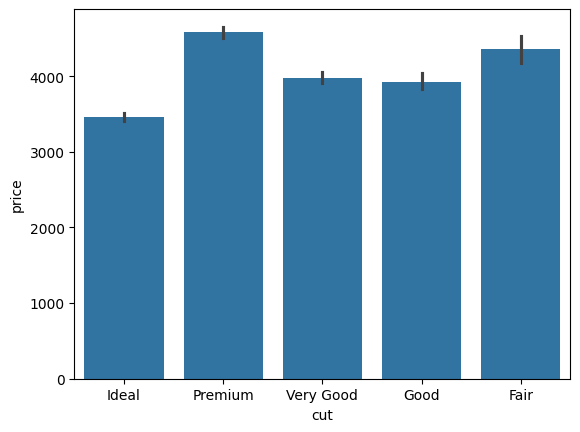

In [ ]:
#STEP 5. 시각화

import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

sns.barplot(data=diamonds, x='cut', y='price', estimator=np.mean)
plt.show()

In [ ]:
#STEP 6. One-Hot Encoding

diamonds_encoded = pd.get_dummies(diamonds, columns=['cut', 'color', 'clarity'])

In [ ]:
#STEP 7. Feature / Target 설정

X = diamonds_encoded.drop('price', axis=1)
y = diamonds_encoded['price']

In [ ]:
#STEP 8. Train/Test 분할

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
#STEP 9. 선형 회귀 모델 학습

from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [ ]:
#STEP 10. 모델 평가

from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MSE:", mse)
print("RMSE:", rmse)
print("R² Score:", r2)

MSE: 1288705.477851674
RMSE: 1135.2116445190622
R² Score: 0.9189331350419387


In [ ]:
#STEP 11. 범주형 데이터 효과 비교

# 범주형 데이터 제외한 모델
X_num = diamonds[['carat', 'depth', 'table']]
y = diamonds['price']

X_train_num, X_test_num, y_train_num, y_test_num = train_test_split(X_num, y, test_size=0.2, random_state=42)

model_num = LinearRegression()
model_num.fit(X_train_num, y_train_num)
y_pred_num = model_num.predict(X_test_num)

print("Without categorical R²:", r2_score(y_test_num, y_pred_num))

Without categorical R²: 0.853185544894256
